# Poluição (MP10), clima e internações respiratórias — Rio Claro/SP, 2023–2025

**Bases**

- CETESB, estação 292 (Rio Claro – Jd. Guanabara), dados horários: MP10, direção e velocidade do vento, temperatura e umidade.
- SIH/SUS (DATASUS), internações de residentes de Rio Claro com CID-10 do capítulo J.

**Roteiro (um bloco por etapa)**

| Bloco | Etapa |
|---|---|
| 0 | Parâmetros e bibliotecas |
| 1 | Carga e diagnóstico das duas bases |
| 2 | Tratamento dos vazios na série horária |
| 3 | Agregação diária da CETESB |
| 4 | Classificações (MP10, temperatura, umidade, vento) |
| 5 | Contagem diária de internações |
| 6 | União das bases e defasagens (lags) |
| 7 | Correlação de Spearman |
| 8 | K-means |
| 9 | Apriori (regras de associação) |

Rode os blocos na ordem. Todos os cortes e limites ficam no Bloco 0; para testar outro valor, altere lá e rode tudo de novo.

## Bloco 0 — Parâmetros e bibliotecas

Se faltar alguma biblioteca, rode uma vez em uma célula: `%pip install pandas numpy scipy scikit-learn matplotlib mlxtend`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

# ---------------- arquivos (na mesma pasta do notebook) ----------------
ARQ_CETESB = "cetesb_rio_claro_2023_2025_unificado.csv"
ARQ_SIH    = "sih_rioclaro_respiratorias.csv"
ARQ_SAIDA  = "base_diaria_rioclaro.csv"

# ---------------- período do estudo ----------------
DATA_INI = "2023-01-01"
DATA_FIM = "2025-12-31"

# ---------------- MP10 (média de 24 h, µg/m³) ----------------
LIMITE_MP10 = 45                      # diretriz da OMS (2021) para a média de 24 h
FAIXAS_MP10 = [0, 45, 100, 150, 250, np.inf]
NOMES_FAIXAS_MP10 = ["BOA", "MODERADA", "RUIM", "MUITO_RUIM", "PESSIMA"]

# ---------------- vento ----------------
SETOR_INI, SETOR_FIM = 90, 135        # graus: origem Cordeirópolis / Santa Gertrudes
VV_CALMARIA = 0.5                     # m/s: abaixo disso a direção não é confiável
PCT_VENTO_VEM = 25                    # % das horas do dia para classificar como "vem do setor"

# ---------------- umidade e temperatura ----------------
UR_SECO = 30                          # % : dia SECO se a mínima do dia ficar abaixo
PERCENTIS_TEMP = [10, 30, 70, 90]     # cortes das 5 classes de temperatura
NOMES_TEMP = ["MUITO_FRIO", "FRIO", "AMENO", "QUENTE", "MUITO_QUENTE"]

# ---------------- dados vazios ----------------
MAX_BURACO_HORAS = 3                  # interpola buracos de até 3 horas seguidas
MIN_HORAS_DIA = 16                    # dia só é válido com pelo menos 16 das 24 horas
MAX_BURACO_DIAS = 3                   # interpola até 3 dias inválidos seguidos

# ---------------- defasagem, internações, k-means, apriori ----------------
LAGS = [1, 2, 3, 4]                   # MP10 de 1 a 4 dias antes
PERCENTIL_INTERN_ALTA = 75            # dia com internações ALTA = acima deste percentil
K_CLUSTERS = 4
SUPORTE_MIN = 0.03                    # 3% dos dias

## Bloco 1 — Carga e diagnóstico

Só leitura: tamanho, período e quantidade de vazios de cada base, antes de qualquer transformação.

In [2]:
cet = pd.read_csv(ARQ_CETESB, sep=";", encoding="utf-8-sig", dtype=str)

# usa as 11 primeiras colunas pela posição, ignorando os nomes alterados e as colunas vazias do fim
cet = cet.iloc[:, :11]
cet.columns = ["DataHora", "Data", "Hora", "Ano", "Mes", "Dia", "MP10", "DV", "VV", "TEMP", "UR"]

cet["DataHora"] = pd.to_datetime(cet["DataHora"], format="%d/%m/%Y %H:%M")
for col in ["MP10", "DV", "VV", "TEMP", "UR"]:
    cet[col] = pd.to_numeric(cet[col].str.replace(",", ".", regex=False), errors="coerce")

cet = cet[["DataHora", "MP10", "DV", "VV", "TEMP", "UR"]].sort_values("DataHora").reset_index(drop=True)

print("CETESB:", cet.shape, "| de", cet["DataHora"].min(), "até", cet["DataHora"].max())
diag = pd.DataFrame({
    "vazios": cet.isna().sum(),
    "% vazio": (cet.isna().mean() * 100).round(2),
}).drop("DataHora")
display(diag)
display(cet.describe().T.round(2))

CETESB: (26304, 6) | de 2023-01-01 01:00:00 até 2026-01-01 00:00:00


,vazios,% vazio
MP10,563,2.14
DV,47,0.18
VV,47,0.18
TEMP,53,0.20
UR,52,0.20


,count,mean,min,25%,50%,75%,max,std
DataHora,26304,2024-07-02 00:30:00,2023-01-01 01:00:00,2023-10-02 00:45:00,2024-07-02 00:30:00,2025-04-02 00:15:00,2026-01-01 00:00:00,NaN
MP10,25741.0,38.736218,0.0,17.0,28.0,49.0,524.0,34.10358
DV,26257.0,198.117759,0.0,111.0,210.0,282.0,888.0,126.519471
VV,26257.0,2.024835,0.0,1.2,1.8,2.6,10.8,1.035437
TEMP,26251.0,23.316868,2.0,19.4,22.8,27.8,41.0,6.043832
UR,26252.0,66.587879,6.0,49.0,71.0,86.0,99.0,21.765425


In [3]:
sih = pd.read_csv(ARQ_SIH, dtype=str)
sih["DT_INTER"] = pd.to_datetime(sih["DT_INTER"])
sih["CAR_INT"] = sih["CAR_INT"].str.zfill(2)

print("SIH:", sih.shape, "| internações de", sih["DT_INTER"].min().date(), "até", sih["DT_INTER"].max().date())
print("\nMunicípio de residência:"); print(sih["MUNIC_RES"].value_counts().to_string())
print("\nCaráter da internação (01 = eletiva, 02 = urgência):"); print(sih["CAR_INT"].value_counts().to_string())
print("\nCapítulo do CID principal:"); print(sih["DIAG_PRINC"].str[0].value_counts().to_string())
print("\nInternações por ano (data da internação):"); print(sih["DT_INTER"].dt.year.value_counts().sort_index().to_string())

SIH: (1946, 17) | internações de 2022-12-06 até 2025-12-27

Município de residência:
MUNIC_RES
354390    1946

Caráter da internação (01 = eletiva, 02 = urgência):
CAR_INT
02    1399
01     547

Capítulo do CID principal:
DIAG_PRINC
J    1946

Internações por ano (data da internação):
DT_INTER
2022     12
2023    628
2024    485
2025    821


## Bloco 2 — Vazios na série horária

1. Garante uma linha para cada hora do período (horas que não vieram no arquivo passam a existir como vazias).
2. Interpola linearmente **apenas buracos de até `MAX_BURACO_HORAS` horas seguidas** em MP10, temperatura, umidade e velocidade do vento. Buracos maiores continuam vazios e são tratados no nível do dia (Bloco 3).
3. A direção do vento (DV) **não** é interpolada: é um ângulo, e a média entre 350° e 10° daria 180°.

In [4]:
def interpola_buracos_curtos(s, tamanho_max):
    # Interpola só as sequências de vazios com até tamanho_max posições; as maiores ficam como estão.
    vazio = s.isna()
    grupo = (vazio != vazio.shift()).cumsum()
    tamanho = vazio.groupby(grupo).transform("sum")
    interpolada = s.interpolate(method="linear", limit_area="inside")
    return s.where(~(vazio & (tamanho <= tamanho_max)), interpolada)


# a CETESB numera as horas de 01:00 a 24:00; no arquivo unificado a hora 24:00 virou 00:00 do dia seguinte
ini = pd.Timestamp(DATA_INI) + pd.Timedelta(hours=1)
fim = pd.Timestamp(DATA_FIM) + pd.Timedelta(days=1)
todas_horas = pd.date_range(ini, fim, freq="h")

hor = cet.set_index("DataHora").reindex(todas_horas)
hor.index.name = "DataHora"

antes = hor.isna().sum()
for col in ["MP10", "TEMP", "UR", "VV"]:
    hor[col] = interpola_buracos_curtos(hor[col], MAX_BURACO_HORAS)
depois = hor.isna().sum()

display(pd.DataFrame({"vazios antes": antes, "preenchidos": antes - depois, "vazios depois": depois}))

,vazios antes,preenchidos,vazios depois
MP10,563,53,510
DV,47,0,47
VV,47,6,41
TEMP,53,12,41
UR,52,11,41


## Bloco 3 — Agregação diária

- **Dia da medição:** a média das 24:00 pertence ao dia que termina, por isso o dia é calculado como `DataHora − 1 hora`.
- **MP10:** média de 24 h (é sobre ela que o limite é definido) e mediana como coluna extra.
- **Temperatura e umidade:** mediana, mínima e máxima do dia.
- **Vento:** percentual das horas do dia com vento vindo do setor `SETOR_INI`–`SETOR_FIM`, ignorando as horas de calmaria (velocidade abaixo de `VV_CALMARIA` ou direção com código acima de 360).
- **Validade:** o dia só vale para uma variável se ela tiver pelo menos `MIN_HORAS_DIA` horas medidas. Dias inválidos são preenchidos por interpolação entre os dias vizinhos (até `MAX_BURACO_DIAS` dias seguidos) e ficam marcados nas colunas `*_PREENCHIDO`.

In [5]:
hor["DIA"] = (hor.index - pd.Timedelta(hours=1)).normalize()

# DV acima de 360 não é ângulo: a CETESB usa códigos (777, 888) para calmaria/vento sem direção definida
print("Horas com DV fora de 0-360 (códigos de calmaria):", int((hor["DV"] > 360).sum()))
hor["VENTO_VALIDO"] = hor["DV"].between(0, 360) & (hor["VV"] >= VV_CALMARIA)
hor["VENTO_SETOR"] = hor["VENTO_VALIDO"] & hor["DV"].between(SETOR_INI, SETOR_FIM)

g = hor.groupby("DIA")
dia = pd.DataFrame({
    "MP10_MEDIA":   g["MP10"].mean(),
    "MP10_MEDIANA": g["MP10"].median(),
    "MP10_N":       g["MP10"].count(),
    "TEMP_MEDIANA": g["TEMP"].median(),
    "TEMP_MIN":     g["TEMP"].min(),
    "TEMP_MAX":     g["TEMP"].max(),
    "TEMP_N":       g["TEMP"].count(),
    "UR_MEDIANA":   g["UR"].median(),
    "UR_MIN":       g["UR"].min(),
    "UR_N":         g["UR"].count(),
    "VV_MEDIANA":   g["VV"].median(),
    "VV_N":         g["VV"].count(),
    "DV_N":         g["DV"].count(),
    "VENTO_HORAS_VALIDAS": g["VENTO_VALIDO"].sum(),
    "VENTO_HORAS_SETOR":   g["VENTO_SETOR"].sum(),
})

# % das horas (sem calmaria) com vento vindo do setor; dia inteiro de calmaria = 0%
dia["VENTO_PCT_SETOR"] = np.where(
    dia["VENTO_HORAS_VALIDAS"] > 0,
    100 * dia["VENTO_HORAS_SETOR"] / dia["VENTO_HORAS_VALIDAS"].where(dia["VENTO_HORAS_VALIDAS"] > 0),
    0.0,
)

# invalida as variáveis dos dias com menos de MIN_HORAS_DIA horas medidas
grupos = {
    "MP10": (["MP10_MEDIA", "MP10_MEDIANA"], "MP10_N"),
    "TEMP": (["TEMP_MEDIANA", "TEMP_MIN", "TEMP_MAX"], "TEMP_N"),
    "UR":   (["UR_MEDIANA", "UR_MIN"], "UR_N"),
    "VV":   (["VV_MEDIANA"], "VV_N"),
    "VENTO": (["VENTO_PCT_SETOR"], "DV_N"),
}
resumo = []
for nome, (colunas, col_n) in grupos.items():
    invalido = dia[col_n] < MIN_HORAS_DIA
    dia.loc[invalido, colunas] = np.nan
    for c in colunas:
        dia[c] = interpola_buracos_curtos(dia[c], MAX_BURACO_DIAS)
    dia[nome + "_PREENCHIDO"] = invalido & dia[colunas[0]].notna()
    resumo.append({
        "variável": nome,
        "dias inválidos": int(invalido.sum()),
        "preenchidos": int(dia[nome + "_PREENCHIDO"].sum()),
        "continuam vazios": int(dia[colunas[0]].isna().sum()),
    })

print("Dias na tabela:", len(dia))
display(pd.DataFrame(resumo))
display(dia.head())

Horas com DV fora de 0-360 (códigos de calmaria): 367
Dias na tabela: 1096


,variável,dias inválidos,preenchidos,continuam vazios
0,MP10,20,12,8
1,TEMP,2,2,0
2,UR,2,2,0
3,VV,2,2,0
4,VENTO,2,2,0


,MP10_MEDIA,MP10_MEDIANA,MP10_N,TEMP_MEDIANA,TEMP_MIN,TEMP_MAX,TEMP_N,UR_MEDIANA,UR_MIN,UR_N,VV_MEDIANA,VV_N,DV_N,VENTO_HORAS_VALIDAS,VENTO_HORAS_SETOR,VENTO_PCT_SETOR,MP10_PREENCHIDO,TEMP_PREENCHIDO,UR_PREENCHIDO,VV_PREENCHIDO,VENTO_PREENCHIDO
DIA,,,,,,,,,,,,,,,,,,,,,
2023-01-01,11.208333,9.0,24,25.30,21.8,30.7,24,70.0,54.0,24,1.80,24,24,24,7,29.166667,False,False,False,False,False
2023-01-02,12.041667,11.5,24,22.85,19.9,33.1,24,79.0,45.0,24,2.10,24,24,23,0,0.000000,False,False,False,False,False
2023-01-03,11.208333,10.0,24,23.65,20.9,28.7,24,84.0,57.0,24,2.15,24,24,24,0,0.000000,False,False,False,False,False
2023-01-04,10.416667,9.5,24,22.15,20.5,28.1,24,88.0,59.0,24,2.05,24,24,24,0,0.000000,False,False,False,False,False
2023-01-05,9.000000,7.5,24,19.10,18.2,20.1,24,96.0,89.0,24,2.60,24,24,24,0,0.000000,False,False,False,False,False


## Bloco 4 — Classificações

| Variável | Regra |
|---|---|
| MP10 | `ACIMA` quando a média de 24 h passa de `LIMITE_MP10` (45 µg/m³, OMS). `MP10_FAIXA` é a faixa do índice de qualidade do ar. |
| Temperatura | 5 classes pelos percentis 10/30/70/90 da mediana diária. A tabela abaixo mostra os °C de cada corte. |
| Umidade | `SECO` se a mínima do dia ficar abaixo de `UR_SECO`; senão `UMIDO`. |
| Vento | `VEM_CORD_SG` se pelo menos `PCT_VENTO_VEM`% das horas vierem do setor; senão `OUTRA_ORIGEM`. |

Graduação da temperatura (mediana diária):


,classe,de (°C),até (°C),dias
0,MUITO_FRIO,11.8,17.6,113
1,FRIO,17.6,20.9,219
2,AMENO,20.9,24.5,436
3,QUENTE,24.5,27.1,218
4,MUITO_QUENTE,27.1,32.6,110



MP10_LIMITE
MP10_LIMITE
DENTRO    738
ACIMA     350
NaN         8

MP10_FAIXA
MP10_FAIXA
BOA           738
MODERADA      323
RUIM           24
NaN             8
MUITO_RUIM      3

UR_CLASSE
UR_CLASSE
UMIDO    803
SECO     293

VENTO_CLASSE
VENTO_CLASSE
OUTRA_ORIGEM    1052
VEM_CORD_SG       44

Dias por faixa do % de horas com vento vindo do setor:
VENTO_PCT_SETOR
[0, 1)       488
[1, 10)      370
[10, 25)     194
[25, 50)      41
[50, 100)      3


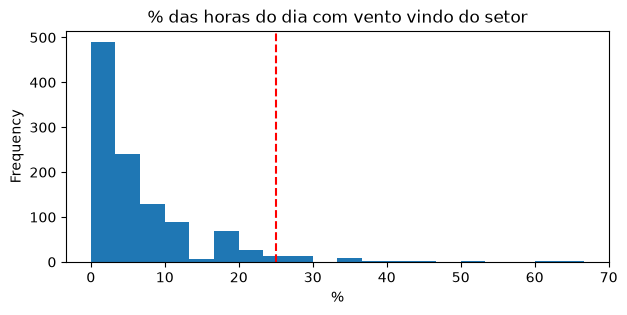

In [6]:
def classe(condicao, se_sim, se_nao, base):
    # Classe binária que preserva o vazio quando a variável de origem está vazia.
    out = pd.Series(np.where(condicao, se_sim, se_nao), index=base.index, dtype="object")
    return out.where(base.notna())


# --- MP10 ---
dia["MP10_LIMITE"] = classe(dia["MP10_MEDIA"] > LIMITE_MP10, "ACIMA", "DENTRO", dia["MP10_MEDIA"])
dia["MP10_FAIXA"] = pd.cut(dia["MP10_MEDIA"], bins=FAIXAS_MP10, labels=NOMES_FAIXAS_MP10,
                           include_lowest=True).astype("object")

# --- temperatura ---
cortes_temp = np.nanpercentile(dia["TEMP_MEDIANA"], PERCENTIS_TEMP)
dia["TEMP_CLASSE"] = pd.cut(dia["TEMP_MEDIANA"], bins=[-np.inf, *cortes_temp, np.inf],
                            labels=NOMES_TEMP).astype("object")

graduacao = pd.DataFrame({
    "classe": NOMES_TEMP,
    "de (°C)": [dia["TEMP_MEDIANA"].min()] + list(cortes_temp),
    "até (°C)": list(cortes_temp) + [dia["TEMP_MEDIANA"].max()],
    "dias": [int((dia["TEMP_CLASSE"] == n).sum()) for n in NOMES_TEMP],
}).round(1)
print("Graduação da temperatura (mediana diária):")
display(graduacao)

# --- umidade ---
dia["UR_CLASSE"] = classe(dia["UR_MIN"] < UR_SECO, "SECO", "UMIDO", dia["UR_MIN"])

# --- vento ---
dia["VENTO_CLASSE"] = classe(dia["VENTO_PCT_SETOR"] >= PCT_VENTO_VEM, "VEM_CORD_SG", "OUTRA_ORIGEM",
                             dia["VENTO_PCT_SETOR"])

for c in ["MP10_LIMITE", "MP10_FAIXA", "UR_CLASSE", "VENTO_CLASSE"]:
    print("\n" + c); print(dia[c].value_counts(dropna=False).to_string())

print("\nDias por faixa do % de horas com vento vindo do setor:")
print(pd.cut(dia["VENTO_PCT_SETOR"], [0, 1, 10, 25, 50, 100], include_lowest=True, right=False).value_counts().sort_index().to_string())

ax = dia["VENTO_PCT_SETOR"].plot.hist(bins=20, figsize=(7, 3), title="% das horas do dia com vento vindo do setor")
ax.axvline(PCT_VENTO_VEM, color="red", linestyle="--"); ax.set_xlabel("%"); plt.show()

## Bloco 5 — Internações por dia

- Fica só o CID-10 do capítulo J, retirando as internações **eletivas** (`CAR_INT = 01`), que são agendadas.
- A data usada é a da internação (`DT_INTER`), dentro do período do estudo.
- Dia sem internação entra como **zero**.

Registros no arquivo: 1946 | capítulo J: 1946 | sem eletivas: 1399 | dentro do período: 1391

Dias com zero internações: 375 de 1096

Distribuição (internações no dia -> quantidade de dias):
INTERNACOES
0    375
1    334
2    205
3    115
4     42
5     16
6      9

Total por ano:
DIA
2023    446
2024    387
2025    558


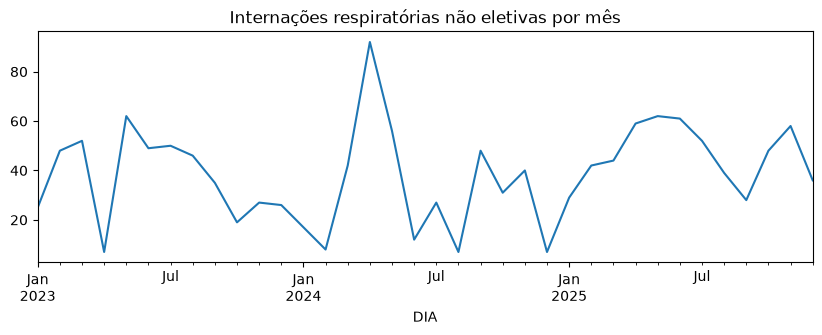

In [7]:
n0 = len(sih)
f = sih[sih["DIAG_PRINC"].str.startswith("J")]
n1 = len(f)
f = f[f["CAR_INT"] != "01"]
n2 = len(f)
f = f[(f["DT_INTER"] >= DATA_INI) & (f["DT_INTER"] <= DATA_FIM)]
n3 = len(f)
print(f"Registros no arquivo: {n0} | capítulo J: {n1} | sem eletivas: {n2} | dentro do período: {n3}")

intern = f.groupby("DT_INTER").size().reindex(dia.index, fill_value=0).rename("INTERNACOES")

print("\nDias com zero internações:", int((intern == 0).sum()), "de", len(intern))
print("\nDistribuição (internações no dia -> quantidade de dias):")
print(intern.value_counts().sort_index().to_string())
print("\nTotal por ano:"); print(intern.groupby(intern.index.year).sum().to_string())

intern.resample("MS").sum().plot(figsize=(10, 3), title="Internações respiratórias não eletivas por mês")
plt.show()

## Bloco 6 — União das bases e defasagens

- Junta as internações à tabela diária da CETESB pela data.
- `MP10_LAG1` … `MP10_LAG4`: MP10 de 1 a 4 dias antes.
- `MP10_MM4`: média do MP10 dos 4 dias anteriores (não inclui o próprio dia).
- `MP10_ULT4D`: `ACIMA` se em algum dos 4 dias anteriores o MP10 passou do limite.
- `INTERN_CLASSE`: `ALTA` quando o dia fica acima do percentil `PERCENTIL_INTERN_ALTA` das internações.

In [8]:
base = dia.join(intern)
base.index.name = "DATA"

for k in LAGS:
    base[f"MP10_LAG{k}"] = base["MP10_MEDIA"].shift(k)

colunas_lag = [f"MP10_LAG{k}" for k in LAGS]
base["MP10_MM4"] = base[colunas_lag].mean(axis=1, skipna=False)

acima_antes = (base[colunas_lag] > LIMITE_MP10).any(axis=1)
base["MP10_ULT4D"] = pd.Series(np.where(acima_antes, "ACIMA", "DENTRO"), index=base.index,
                               dtype="object").where(base[colunas_lag].notna().all(axis=1))

corte_intern = base["INTERNACOES"].quantile(PERCENTIL_INTERN_ALTA / 100)
base["INTERN_CLASSE"] = np.where(base["INTERNACOES"] > corte_intern, "ALTA", "NORMAL")
print(f"Percentil {PERCENTIL_INTERN_ALTA} das internações = {corte_intern:.0f} -> dia ALTA = mais de {corte_intern:.0f} internações")
print(base["INTERN_CLASSE"].value_counts().to_string())

base["ANO"] = base.index.year
base["MES"] = base.index.month
base["DIA_SEMANA"] = base.index.dayofweek      # 0 = segunda

base.to_csv(ARQ_SAIDA, sep=";", encoding="utf-8-sig", float_format="%.2f")
print("\nTabela diária gravada em", ARQ_SAIDA, "|", base.shape)
display(base.head(8))

Percentil 75 das internações = 2 -> dia ALTA = mais de 2 internações
INTERN_CLASSE
NORMAL    914
ALTA      182

Tabela diária gravada em base_diaria_rioclaro.csv | (1096, 37)


,MP10_MEDIA,MP10_MEDIANA,MP10_N,TEMP_MEDIANA,TEMP_MIN,TEMP_MAX,TEMP_N,UR_MEDIANA,UR_MIN,UR_N,VV_MEDIANA,VV_N,DV_N,VENTO_HORAS_VALIDAS,VENTO_HORAS_SETOR,VENTO_PCT_SETOR,MP10_PREENCHIDO,TEMP_PREENCHIDO,UR_PREENCHIDO,VV_PREENCHIDO,VENTO_PREENCHIDO,MP10_LIMITE,MP10_FAIXA,TEMP_CLASSE,UR_CLASSE,VENTO_CLASSE,INTERNACOES,MP10_LAG1,MP10_LAG2,MP10_LAG3,MP10_LAG4,MP10_MM4,MP10_ULT4D,INTERN_CLASSE,ANO,MES,DIA_SEMANA
DATA,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2023-01-01,11.208333,9.0,24,25.30,21.8,30.7,24,70.0,54.0,24,1.80,24,24,24,7,29.166667,False,False,False,False,False,DENTRO,BOA,QUENTE,UMIDO,VEM_CORD_SG,2,NaN,NaN,NaN,NaN,NaN,NaN,NORMAL,2023,1,6
2023-01-02,12.041667,11.5,24,22.85,19.9,33.1,24,79.0,45.0,24,2.10,24,24,23,0,0.000000,False,False,False,False,False,DENTRO,BOA,AMENO,UMIDO,OUTRA_ORIGEM,2,11.208333,NaN,NaN,NaN,NaN,NaN,NORMAL,2023,1,0
2023-01-03,11.208333,10.0,24,23.65,20.9,28.7,24,84.0,57.0,24,2.15,24,24,24,0,0.000000,False,False,False,False,False,DENTRO,BOA,AMENO,UMIDO,OUTRA_ORIGEM,0,12.041667,11.208333,NaN,NaN,NaN,NaN,NORMAL,2023,1,1
2023-01-04,10.416667,9.5,24,22.15,20.5,28.1,24,88.0,59.0,24,2.05,24,24,24,0,0.000000,False,False,False,False,False,DENTRO,BOA,AMENO,UMIDO,OUTRA_ORIGEM,1,11.208333,12.041667,11.208333,NaN,NaN,NaN,NORMAL,2023,1,2
2023-01-05,9.000000,7.5,24,19.10,18.2,20.1,24,96.0,89.0,24,2.60,24,24,24,0,0.000000,False,False,False,False,False,DENTRO,BOA,FRIO,UMIDO,OUTRA_ORIGEM,0,10.416667,11.208333,12.041667,11.208333,11.218750,DENTRO,NORMAL,2023,1,3
2023-01-06,11.041667,11.0,24,18.65,17.6,22.2,24,79.5,68.0,24,4.00,24,24,24,0,0.000000,False,False,False,False,False,DENTRO,BOA,FRIO,UMIDO,OUTRA_ORIGEM,0,9.000000,10.416667,11.208333,12.041667,10.666667,DENTRO,NORMAL,2023,1,4
2023-01-07,12.333333,12.5,24,20.15,17.3,25.2,24,73.0,60.0,24,3.80,24,24,24,0,0.000000,False,False,False,False,False,DENTRO,BOA,FRIO,UMIDO,OUTRA_ORIGEM,0,11.041667,9.000000,10.416667,11.208333,10.416667,DENTRO,NORMAL,2023,1,5
2023-01-08,11.625000,10.5,24,21.80,17.3,25.5,24,78.0,66.0,24,2.75,24,24,24,1,4.166667,False,False,False,False,False,DENTRO,BOA,AMENO,UMIDO,OUTRA_ORIGEM,0,12.333333,11.041667,9.000000,10.416667,10.697917,DENTRO,NORMAL,2023,1,6


## Bloco 7 — Correlação de Spearman

A correlação de Spearman trabalha com postos (ranking), por isso não exige distribuição normal e serve para contagens pequenas como as internações diárias.

- **rho** vai de −1 a +1; perto de 0 = sem relação monotônica.
- **p** abaixo de 0,05 = dificilmente a relação observada é fruto do acaso.

Depois, a média de internações em cada classe criada no Bloco 4.

,rho,p,n dias
variável,,,
MP10_MEDIA,0.0975,0.0013,1088
MP10_LAG1,0.1068,0.0004,1087
MP10_LAG2,0.0802,0.0082,1086
MP10_LAG3,0.0728,0.0164,1085
MP10_LAG4,0.0786,0.0096,1084
MP10_MM4,0.0974,0.0014,1078
TEMP_MEDIANA,-0.0514,0.0889,1096
TEMP_MIN,-0.0698,0.0207,1096
UR_MEDIANA,0.0282,0.3516,1096


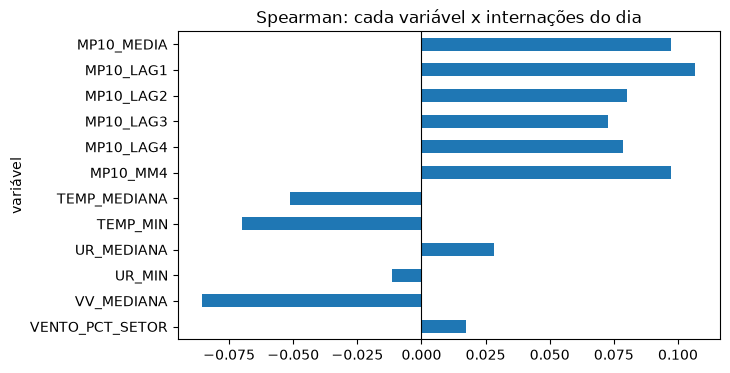

In [9]:
variaveis = ["MP10_MEDIA"] + colunas_lag + ["MP10_MM4", "TEMP_MEDIANA", "TEMP_MIN", "UR_MEDIANA",
                                              "UR_MIN", "VV_MEDIANA", "VENTO_PCT_SETOR"]
linhas = []
for v in variaveis:
    d = base[[v, "INTERNACOES"]].dropna()
    rho, p = stats.spearmanr(d[v], d["INTERNACOES"])
    linhas.append({"variável": v, "rho": rho, "p": p, "n dias": len(d)})
spearman = pd.DataFrame(linhas).set_index("variável")
display(spearman.round(4))

ax = spearman["rho"].plot.barh(figsize=(7, 4), title="Spearman: cada variável x internações do dia")
ax.axvline(0, color="black", linewidth=0.8); ax.invert_yaxis(); plt.show()

In [10]:
for c in ["MP10_LIMITE", "MP10_ULT4D", "MP10_FAIXA", "TEMP_CLASSE", "UR_CLASSE", "VENTO_CLASSE"]:
    t = base.groupby(c)["INTERNACOES"].agg(dias="count", media="mean", mediana="median")
    t["% dias ALTA"] = base.groupby(c)["INTERN_CLASSE"].apply(lambda s: 100 * (s == "ALTA").mean())
    print("\n" + c); display(t.round(2))


MP10_LIMITE


,dias,media,mediana,% dias ALTA
MP10_LIMITE,,,,
ACIMA,350,1.41,1.0,19.43
DENTRO,738,1.21,1.0,15.45



MP10_ULT4D


,dias,media,mediana,% dias ALTA
MP10_ULT4D,,,,
ACIMA,510,1.39,1.0,19.02
DENTRO,568,1.18,1.0,14.96



MP10_FAIXA


,dias,media,mediana,% dias ALTA
MP10_FAIXA,,,,
BOA,738,1.21,1.0,15.45
MODERADA,323,1.44,1.0,20.12
MUITO_RUIM,3,1.33,1.0,0.00
RUIM,24,1.00,1.0,12.50


... (2 outputs left out)


UR_CLASSE


,dias,media,mediana,% dias ALTA
UR_CLASSE,,,,
SECO,293,1.16,1.0,14.33
UMIDO,803,1.31,1.0,17.43



VENTO_CLASSE


,dias,media,mediana,% dias ALTA
VENTO_CLASSE,,,,
OUTRA_ORIGEM,1052,1.27,1.0,16.44
VEM_CORD_SG,44,1.34,1.0,20.45


## Bloco 8 — K-means

O k-means agrupa os dias em perfis parecidos de poluição e clima. As internações **não** entram no agrupamento: elas são comparadas depois, entre os grupos.

1. Padronização (`StandardScaler`): sem ela, a variável de maior escala dominaria a distância.
2. Cotovelo e silhueta para apoiar a escolha de `K_CLUSTERS`.
3. Perfil de cada grupo e teste de Kruskal-Wallis para saber se as internações diferem entre os grupos.

Dias usados no k-means: 1076 de 1096


c:\Users\ferna\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\ferna\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\ferna\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\ferna\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

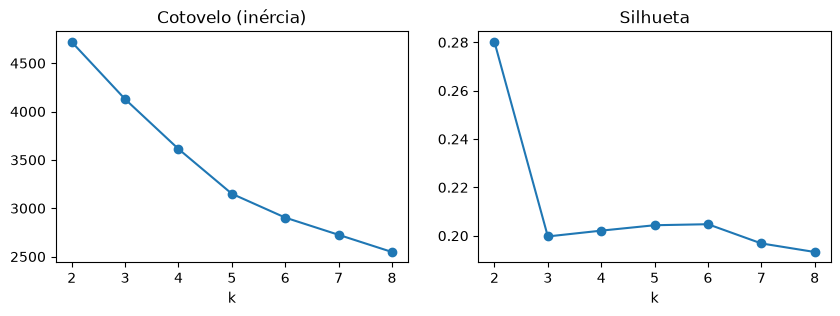

In [11]:
VARS_KMEANS = ["MP10_MEDIA", "MP10_MM4", "TEMP_MEDIANA", "UR_MIN", "VV_MEDIANA", "VENTO_PCT_SETOR"]

km_base = base.dropna(subset=VARS_KMEANS).copy()
X = StandardScaler().fit_transform(km_base[VARS_KMEANS])
print("Dias usados no k-means:", len(km_base), "de", len(base))

ks = range(2, 9)
inercia, silhueta = [], []
for k in ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inercia.append(m.inertia_)
    silhueta.append(silhouette_score(X, m.labels_))

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(list(ks), inercia, marker="o"); ax[0].set_title("Cotovelo (inércia)"); ax[0].set_xlabel("k")
ax[1].plot(list(ks), silhueta, marker="o"); ax[1].set_title("Silhueta"); ax[1].set_xlabel("k")
plt.show()

In [12]:
modelo = KMeans(n_clusters=K_CLUSTERS, n_init=10, random_state=42).fit(X)
km_base["CLUSTER"] = modelo.labels_
base["CLUSTER"] = km_base["CLUSTER"]

perfil = km_base.groupby("CLUSTER")[VARS_KMEANS + ["INTERNACOES"]].mean()
perfil.insert(0, "dias", km_base.groupby("CLUSTER").size())
perfil["% dias ALTA"] = km_base.groupby("CLUSTER")["INTERN_CLASSE"].apply(lambda s: 100 * (s == "ALTA").mean())
print("Perfil dos grupos (médias):")
display(perfil.round(2))

amostras = [grp["INTERNACOES"].values for _, grp in km_base.groupby("CLUSTER")]
h, p = stats.kruskal(*amostras)
print(f"Kruskal-Wallis das internações entre os grupos: H = {h:.2f}, p = {p:.4f}")

for c in ["TEMP_CLASSE", "UR_CLASSE", "VENTO_CLASSE", "MP10_LIMITE"]:
    print("\n% de cada classe dentro do grupo —", c)
    display((pd.crosstab(km_base["CLUSTER"], km_base[c], normalize="index") * 100).round(1))

Perfil dos grupos (médias):


c:\Users\ferna\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(


,dias,MP10_MEDIA,MP10_MM4,TEMP_MEDIANA,UR_MIN,VV_MEDIANA,VENTO_PCT_SETOR,INTERNACOES,% dias ALTA
CLUSTER,,,,,,,,,
0,90,31.14,36.26,21.70,38.32,2.54,24.47,1.36,15.56
1,320,20.48,28.00,20.96,55.46,1.99,4.17,1.27,18.12
2,315,67.54,62.55,21.06,27.52,1.60,3.14,1.34,18.10
3,351,30.35,26.83,25.59,35.70,1.86,5.45,1.22,15.10


Kruskal-Wallis das internações entre os grupos: H = 3.25, p = 0.3547

% de cada classe dentro do grupo — TEMP_CLASSE


TEMP_CLASSE,AMENO,FRIO,MUITO_FRIO,MUITO_QUENTE,QUENTE
CLUSTER,,,,,
0,37.8,30.0,11.1,5.6,15.6
1,61.6,20.3,15.0,0.0,3.1
2,29.8,34.3,17.5,6.0,12.4
3,28.8,2.8,0.0,24.5,43.9



% de cada classe dentro do grupo — UR_CLASSE


UR_CLASSE,SECO,UMIDO
CLUSTER,,
0,21.1,78.9
1,0.9,99.1
2,57.1,42.9
3,22.5,77.5



% de cada classe dentro do grupo — VENTO_CLASSE


VENTO_CLASSE,OUTRA_ORIGEM,VEM_CORD_SG
CLUSTER,,
0,55.6,44.4
1,99.7,0.3
2,99.7,0.3
3,99.7,0.3



% de cada classe dentro do grupo — MP10_LIMITE


MP10_LIMITE,ACIMA,DENTRO
CLUSTER,,
0,13.3,86.7
1,0.9,99.1
2,88.9,11.1
3,13.4,86.6


## Bloco 9 — Apriori (regras de associação)

Cada dia vira uma "cesta" com as suas classes (MP10, temperatura, umidade, vento e internações). O Apriori procura combinações que aparecem junto com `INTERN=ALTA`.

- **suporte:** fração dos dias em que a combinação inteira acontece (condições + internações ALTA); `dias_regra` é esse número em dias.
- **confiança:** entre os dias com as condições, fração que teve internações ALTA.
- **lift:** quantas vezes a combinação aumenta a chance de um dia ALTA em relação ao acaso (acima de 1 = associação positiva).

Regra com suporte muito baixo se apoia em poucos dias; por isso o mínimo de `SUPORTE_MIN`.

In [13]:
from mlxtend.frequent_patterns import apriori, association_rules

COLS_APRIORI = {
    "MP10_LIMITE": "MP10_DIA",
    "MP10_ULT4D": "MP10_4D_ANTES",
    "TEMP_CLASSE": "TEMP",
    "UR_CLASSE": "UR",
    "VENTO_CLASSE": "VENTO",
    "INTERN_CLASSE": "INTERN",
}
cestas = base[list(COLS_APRIORI)].dropna().rename(columns=COLS_APRIORI)
onehot = pd.get_dummies(cestas, prefix_sep="=").astype(bool)
print("Dias usados no Apriori:", len(onehot), "| itens:", onehot.shape[1])

frequentes = apriori(onehot, min_support=SUPORTE_MIN, use_colnames=True)
try:
    regras = association_rules(frequentes, metric="lift", min_threshold=1.0)
except TypeError:      # versões do mlxtend que exigem num_itemsets
    regras = association_rules(frequentes, num_itemsets=len(onehot), metric="lift", min_threshold=1.0)

alvo = regras[regras["consequents"] == frozenset({"INTERN=ALTA"})].copy()
alvo["condições"] = alvo["antecedents"].apply(lambda s: " + ".join(sorted(s)))
alvo["dias_regra"] = (alvo["support"] * len(onehot)).round().astype(int)
alvo = alvo.sort_values("lift", ascending=False)[["condições", "dias_regra", "support", "confidence", "lift"]]

print("Proporção de dias ALTA na base (confiança de referência):", round(onehot["INTERN=ALTA"].mean(), 3))
print("Regras que levam a INTERN=ALTA:", len(alvo))
display(alvo.head(20).reset_index(drop=True).round(3))

Dias usados no Apriori: 1076 | itens: 15
Proporção de dias ALTA na base (confiança de referência): 0.169
Regras que levam a INTERN=ALTA: 26


,condições,dias_regra,support,confidence,lift
0,MP10_DIA=ACIMA + UR=UMIDO + VENTO=OUTRA_ORIGEM,36,0.033,0.263,1.554
1,MP10_DIA=ACIMA + UR=UMIDO,36,0.033,0.259,1.531
2,TEMP=FRIO + UR=UMIDO + VENTO=OUTRA_ORIGEM,35,0.033,0.238,1.408
3,TEMP=FRIO + UR=UMIDO,35,0.033,0.223,1.318
4,MP10_4D_ANTES=ACIMA + UR=UMIDO + VENTO=OUTRA_O...,61,0.057,0.213,1.261
5,MP10_4D_ANTES=ACIMA + UR=UMIDO,62,0.058,0.211,1.247
6,MP10_DIA=ACIMA,68,0.063,0.199,1.176
7,TEMP=FRIO + VENTO=OUTRA_ORIGEM,39,0.036,0.198,1.170
8,MP10_DIA=ACIMA + VENTO=OUTRA_ORIGEM,66,0.061,0.198,1.168
9,MP10_4D_ANTES=ACIMA + MP10_DIA=ACIMA,60,0.056,0.196,1.159


## Leitura dos resultados

- Spearman, k-means e Apriori mostram **associação**, não causa. Outros fatores sazonais (por exemplo, circulação de vírus respiratórios no inverno) acompanham o frio e a seca e podem explicar parte do efeito.
- A estação mede o ar em um ponto de Rio Claro; a exposição real de cada pessoa varia.
- As internações do fim de 2025 podem estar incompletas se parte delas foi faturada em 2026.

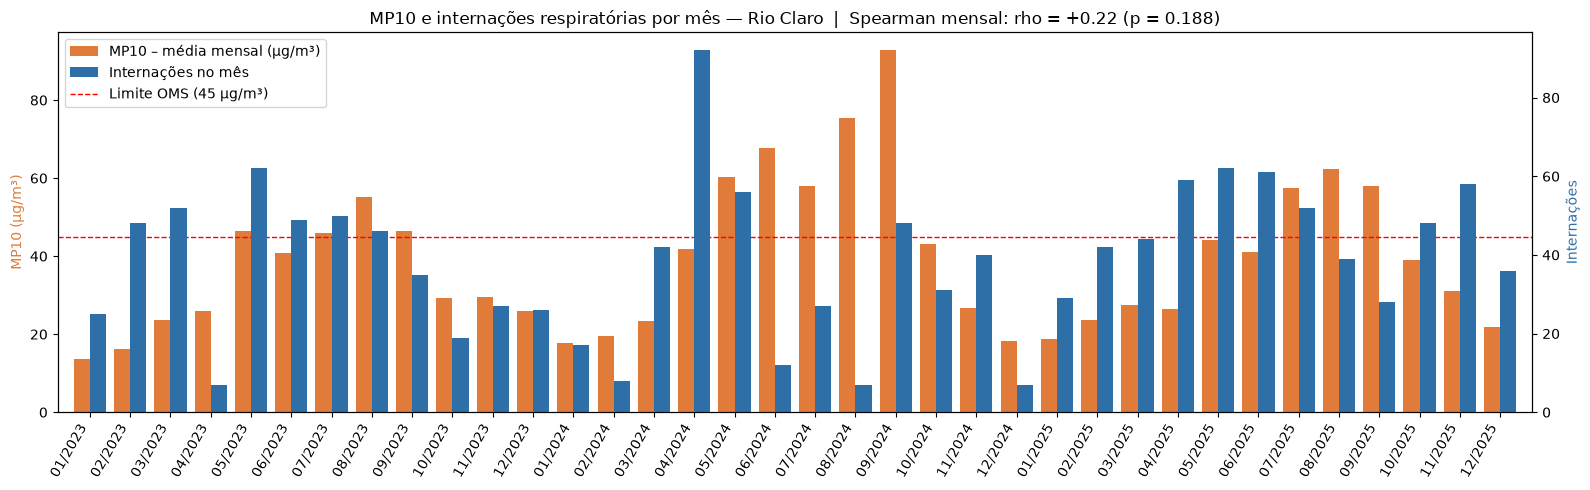

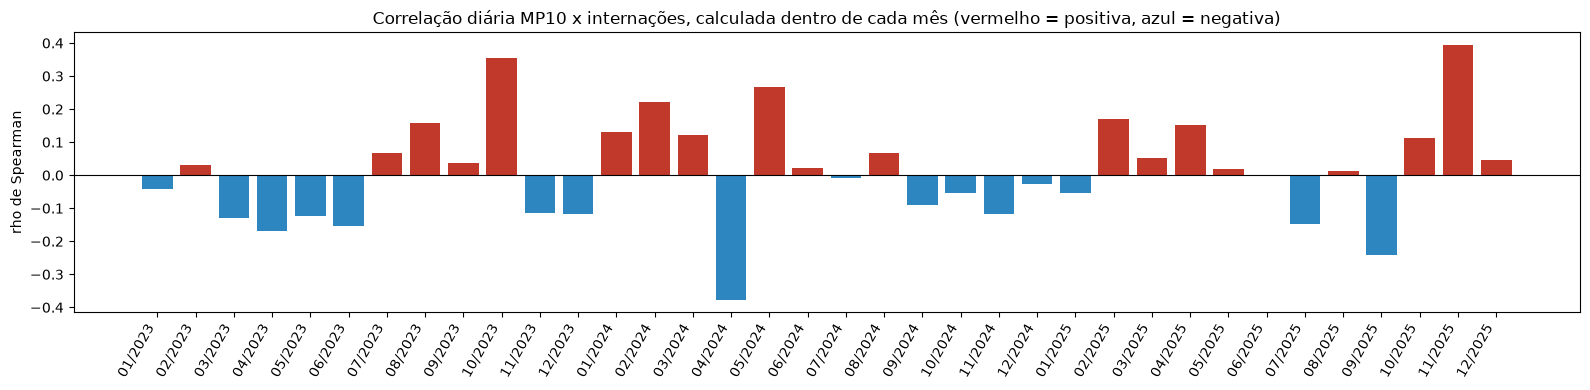

Meses com correlação positiva: 19 | negativa: 17 | sem cálculo: 0


,MP10,INTERNACOES,RHO_NO_MES
DATA,,,
2023-01-01,13.76,25,-0.04
2023-02-01,16.30,48,0.03
2023-03-01,23.58,52,-0.13
2023-04-01,25.93,7,-0.17
2023-05-01,46.33,62,-0.12
2023-06-01,40.84,49,-0.15
2023-07-01,45.94,50,0.07
2023-08-01,55.07,46,0.16
2023-09-01,46.53,35,0.04


In [14]:
# ---------------- Bloco 10 — MP10 x internações, mês a mês ----------------
mensal = pd.DataFrame({
    "MP10": base["MP10_MEDIA"].resample("MS").mean(),        # média mensal do MP10 (µg/m³)
    "INTERNACOES": base["INTERNACOES"].resample("MS").sum(), # total de internações no mês
})
rotulos = mensal.index.strftime("%m/%Y")
x = np.arange(len(mensal))
largura = 0.4

# --- Gráfico 1: barras lado a lado, um par por mês (dois eixos, pois as escalas são diferentes) ---
fig, ax1 = plt.subplots(figsize=(16, 5))
ax2 = ax1.twinx()
b1 = ax1.bar(x - largura / 2, mensal["MP10"], largura, color="#E07B39", label="MP10 – média mensal (µg/m³)")
b2 = ax2.bar(x + largura / 2, mensal["INTERNACOES"], largura, color="#2E6FA7", label="Internações no mês")
linha = ax1.axhline(LIMITE_MP10, color="red", linestyle="--", linewidth=1, label=f"Limite OMS ({LIMITE_MP10} µg/m³)")

ax1.set_ylabel("MP10 (µg/m³)", color="#E07B39")
ax2.set_ylabel("Internações", color="#2E6FA7")
ax1.set_xticks(x)
ax1.set_xticklabels(rotulos, rotation=60, ha="right")
ax1.set_xlim(-0.8, len(mensal) - 0.2)

rho_m, p_m = stats.spearmanr(mensal["MP10"], mensal["INTERNACOES"], nan_policy="omit")
ax1.set_title(f"MP10 e internações respiratórias por mês — Rio Claro  |  Spearman mensal: rho = {rho_m:+.2f} (p = {p_m:.3f})")
ax1.legend(handles=[b1, b2, linha], loc="upper left")
plt.tight_layout(); plt.show()

# --- Gráfico 2: correlação de Spearman dentro de cada mês (dias do mês: MP10 x internações) ---
def rho_do_mes(g):
    d = g[["MP10_MEDIA", "INTERNACOES"]].dropna()
    if len(d) < 10 or d["MP10_MEDIA"].nunique() < 2 or d["INTERNACOES"].nunique() < 2:
        return np.nan
    return stats.spearmanr(d["MP10_MEDIA"], d["INTERNACOES"])[0]

rho_mes = pd.Series({mes: rho_do_mes(g) for mes, g in base.groupby(pd.Grouper(freq="MS"))})
cores = np.where(rho_mes >= 0, "#C0392B", "#2E86C1")     # vermelho = positiva, azul = negativa

fig, ax = plt.subplots(figsize=(16, 4))
ax.bar(x, rho_mes.values, color=cores)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(rotulos, rotation=60, ha="right")
ax.set_ylabel("rho de Spearman")
ax.set_title("Correlação diária MP10 x internações, calculada dentro de cada mês (vermelho = positiva, azul = negativa)")
plt.tight_layout(); plt.show()

print("Meses com correlação positiva:", int((rho_mes > 0).sum()), "| negativa:", int((rho_mes < 0).sum()),
      "| sem cálculo:", int(rho_mes.isna().sum()))
display(mensal.assign(RHO_NO_MES=rho_mes.values).round(2))